In [1]:

from functions import *
df = pd.read_excel("../data/raw/NIMS_FATIGUE.xlsx")
print(df.shape)
print(df.columns.tolist())

(2793, 20)
['Heat', 'Testing Material', 'DS No. PDF', 'Reduction Ratio', 'dA', 'dB', 'dC', 'Normalizing temp', 'Quenching temp', 'Tempering temp', 'Upper yield stress', '0.2% proof stress ', 'Tensile strength', 'True fracture stress', 'Elongation', 'Reduction of area', 'Vickers hardness', 'Type of test', 'σa', 'Nf']


In [2]:
x = df.drop(columns=['Nf'])
y = df['Nf']
print("x shape:", x.shape)
print("y shape:", y.shape)

x shape: (2793, 19)
y shape: (2793,)


In [3]:
# Count missing values in each inpuut
# to identify columns that need preprocessing
missing_values = df.isnull().sum()
print("Missing values in each column:", missing_values)
# Display the data type of each input to help identify categorical columns that need encoding.
print(x.dtypes)

Missing values in each column: Heat                      0
Testing Material          0
DS No. PDF                0
Reduction Ratio           0
dA                        0
dB                        0
dC                        0
Normalizing temp         71
Quenching temp          336
Tempering temp          336
Upper yield stress      145
0.2% proof stress         0
Tensile strength          0
True fracture stress    145
Elongation                0
Reduction of area         0
Vickers hardness          0
Type of test              0
σa                        0
Nf                        0
dtype: int64
Heat                        str
Testing Material            str
DS No. PDF                int64
Reduction Ratio           int64
dA                      float64
dB                      float64
dC                      float64
Normalizing temp        float64
Quenching temp          float64
Tempering temp          float64
Upper yield stress      float64
0.2% proof stress         int64
Tensile stre

In [4]:
# Select columns with the object data type and display their names and example values.
object_columns = x.select_dtypes(include=['object']).columns
print("object columns:", object_columns.tolist())
for col in object_columns:
    print(f"\n{col}:")
    print(x[col].unique()[:10])

object columns: ['Heat', 'Testing Material', 'Type of test']

Heat:
<StringArray>
['A', 'B', 'C', 'D', 'E', 'F', 'H', 'I', 'J', 'K']
Length: 10, dtype: str

Testing Material:
<StringArray>
['S25C', 'S35C', 'S40C', 'S45C', 'S55C']
Length: 5, dtype: str

Type of test:
<StringArray>
['Rotating bending', 'Uniaxial loading']
Length: 2, dtype: str


C:\Users\Leili\AppData\Local\Temp\ipykernel_37588\1558885827.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_columns = x.select_dtypes(include=['object']).columns


In [5]:
# count the number of unique values in each categorical feature. this helps to undrestand which feature may require encoding.
categorical_columns = ["Heat", "Testing Material", "Type of test"]
for col in categorical_columns:
    print(f"{col}: {x[col].nunique()} unique values")

Heat: 12 unique values
Testing Material: 5 unique values
Type of test: 2 unique values


Target variable analysis
to examine the distribution of the target variavle(Nf) which represents the number of cycles to failure. this helps to undrestand the range and variation in fatigue lifetime before selecting regression models.

In [6]:
# display summary statistics for the target variable(Nf) to help undrestand the range and distribution of fatigue lifetime.
print(y.describe())

count    2.793000e+03
mean     6.945012e+07
std      6.936210e+08
min      1.010000e+04
25%      1.680000e+05
50%      5.260000e+05
75%      1.000000e+07
max      1.000000e+10
Name: Nf, dtype: float64


Distribution of fatigue lifetime using a histogram.since Nf values vary over a wide range we use a logarithmic transformation to make the distribution easier to undrestand and assess its suitability for regression modeling.

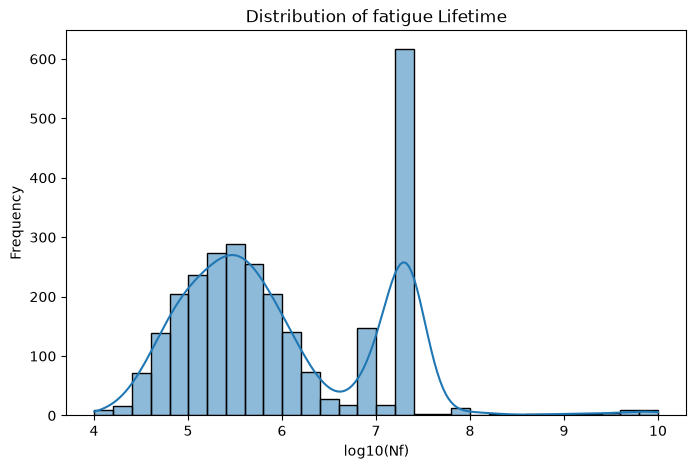

In [7]:
# transform Nf using Log10 to reduce the scale of large values.
log_nf = np.log10(y)
plt.figure(figsize=(8, 5))
sns.histplot(log_nf, bins=30, kde=True)
plt.title('Distribution of fatigue Lifetime')
plt.xlabel("log10(Nf)")
plt.ylabel("Frequency")

plt.show()

High lifetime values
the histogram shows a large concentration of observations near 10 milion cycles. we examine the frequency of this value to investigate whether it could present a fatigue testing limit rather than an actual failure lifetime.

In [8]:
count_10m= ( y == 10_000_000).sum()
print(f"Number of samples with Nf = 10,000,000: {count_10m}")

Number of samples with Nf = 10,000,000: 126


frequency of Nf = 10 milion Cycles, Calculated the number and percentage of observations with Nf equal to 10 milion cycles to investigate the concentration observed in the histogram


In [9]:
# count observations with Nf equal to 10 million
percentage_10m = (count_10m / len(y)) * 100
print("Number of observations:", count_10m)
print(f"Percentage of observations: {percentage_10m:.2f}%")
# Display the 10 most frequently recorded fatigue lifetime values.This helps identify possible testing limits in the dataset.
print(y.value_counts().head(10))

Number of observations: 126
Percentage of observations: 4.51%
Nf
2.120000e+07    584
1.000000e+07    126
1.000000e+10     10
1.150000e+05      9
1.000000e+08      9
2.360000e+05      8
1.030000e+05      8
2.320000e+05      7
2.180000e+05      7
1.110000e+05      7
Name: count, dtype: int64


Our result of 4.51% does not prove that these observations are runouts. We need more information from the dataset documentation.

*Out of 2,793 observations, 126 (4.51%) have a recorded fatigue lifetime of exactly 10 million cycles. This concentration may indicate a predefined testing limit. Further investigation is needed to determine whether these observations represent actual failures or runouts.

In [10]:
# Select observations with Nf equal to 21.2 million cycles.
# Examine their testing materials, test types, and stress amplitudes.

samples_21m = df[df["Nf"] == 21_200_000]

# Display the first 10 matching observations.
print(samples_21m[
    ["Testing Material", "Type of test", "σa", "Nf"]
].head(10))

   Testing Material      Type of test   σa          Nf
14             S25C  Rotating bending  230  21200000.0
15             S25C  Rotating bending  230  21200000.0
16             S25C  Rotating bending  220  21200000.0
17             S25C  Rotating bending  220  21200000.0
18             S25C  Rotating bending  220  21200000.0
38             S25C  Rotating bending  230  21200000.0
39             S25C  Rotating bending  230  21200000.0
40             S25C  Rotating bending  230  21200000.0
54             S25C  Rotating bending  230  21200000.0
55             S25C  Rotating bending  230  21200000.0


What is stress amplitude (σa)?
Stress amplitude tells us how much the applied stress varies during cyclic loading, higher stress amplitudes lead to shorter fatigue lifetimes.

What is stress amplitude (σa)?
Stress amplitude tells us how much the applied stress varies during cyclic loading, higher stress amplitudes lead to shorter fatigue lifetimes.

In [11]:
# Count the number of observations for each steel grade.
print("Testing materials:")
print(samples_21m["Testing Material"].value_counts())

# Count the number of observations for each testing method.
print("\nTest types:")
print(samples_21m["Type of test"].value_counts())

# Examine the range of applied stress amplitudes.
print("\nStress amplitude:")
print(samples_21m["σa"].describe())

Testing materials:
Testing Material
S25C    236
S45C    177
S55C    171
Name: count, dtype: int64

Test types:
Type of test
Rotating bending    584
Name: count, dtype: int64

Stress amplitude:
count    584.000000
mean     402.046233
std       69.715542
min      220.000000
25%      370.000000
50%      410.000000
75%      442.500000
max      580.000000
Name: σa, dtype: float64


In this step, we compare the most frequently recorded fatigue lifetime values for each testing method. This helps us investigate whether repeated Nf values are related to specific testing procedures or possible stopping limits.

In [12]:
for test_type, group in df.groupby("Type of test"):
    print(f"\nTest type: {test_type}")
    print(group["Nf"].value_counts().head(5))


Test type: Rotating bending
Nf
21200000.0    584
115000.0        9
103000.0        8
218000.0        7
1140000.0       7
Name: count, dtype: int64

Test type: Uniaxial loading
Nf
1.000000e+07    126
1.000000e+08      9
1.000000e+10      5
1.160000e+05      3
1.240000e+05      3
Name: count, dtype: int64


The most frequent fatigue lifetime differs between the two testing methods. For rotating bending, 584 observations have Nf = 21.2 million cycles, while for uniaxial loading, 126 observations have Nf = 10 million cycles. These repeated values may be associated with test stopping limits or runouts. However, this cannot be confirmed without additional information about the testing procedures

We examine the data sheet identifiers to help locate the original experimental documentation and investigate possible runouts.

In [13]:
print(df["DS No. PDF"].unique())
df.groupby(["DS No. PDF", "Type of test"]).size()

[  1  38   2  39  97 102   3  44   4]


DS No. PDF  Type of test    
1           Rotating bending    207
            Uniaxial loading     66
2           Rotating bending    745
            Uniaxial loading     59
3           Rotating bending    667
            Uniaxial loading     58
4           Rotating bending    652
            Uniaxial loading     60
38          Uniaxial loading     21
39          Uniaxial loading     57
44          Uniaxial loading     56
97          Rotating bending     46
            Uniaxial loading     55
102         Rotating bending     14
            Uniaxial loading     30
dtype: int64

The dataset contains nine unique data sheet identifiers. We examine how these identifiers are associated with different fatigue testing methods to better understand the organization of the experimental data.

In this step, we examine how different steel grades are distributed across the data sheets. This helps us understand possible relationships between observations and supports selecting an appropriate training and testing strategy.

In [14]:
material_distribution = pd.crosstab(
    df["DS No. PDF"],
    df["Testing Material"]
)
print(material_distribution)

Testing Material  S25C  S35C  S40C  S45C  S55C
DS No. PDF                                    
1                  273     0     0     0     0
2                  804     0     0     0     0
3                    0     0     0   725     0
4                    0     0     0     0   712
38                  21     0     0     0     0
39                   0    57     0     0     0
44                   0     0     0    56     0
97                   0     0   101     0     0
102                  0     0    44     0     0


In this step, we examine the relationship between data sheet identifiers and steel heat groups. Specimens from the same heat may share material properties, so understanding these groups is important when selecting a training and testing strategy.

In [15]:
# Count the number of observations for each data sheet and heat.
# This helps identify how specimens are grouped within the dataset.

heat_distribution = pd.crosstab(
    df["DS No. PDF"],
    df["Heat"]
)

print(heat_distribution)

Heat         A   B   C   D   E   F   G   H   I   J   K   L
DS No. PDF                                                
1           37  39  33  33  19  19   0  20  17  22  17  17
2           79  75  71  85  66  69  58  61  59  57  64  60
3           76  73  75  80  65  60   0  61  57  57  61  60
4           71  76  81  72  59  62  58  58  57  61   0  57
38           0   0   0   7   7   0   0   0   0   7   0   0
39           0   0  14   0   0   0  14   0   0   0  29   0
44           0  14   0   0   0  14   0   0  28   0   0   0
97          73  28   0   0   0   0   0   0   0   0   0   0
102         13  31   0   0   0   0   0   0   0   0   0   0


In this step, we create group identifiers by combining the data sheet number and heat label. This allows us to distinguish heat groups from different data sheets and prepare for a group-based train/test split.

In [16]:
# Combine the data sheet number and heat label.
# This creates an identifier for each data-sheet/heat combination.

groups = (
    df["DS No. PDF"].astype(str)
    + "_"
    + df["Heat"].astype(str)
)

# Display the first 10 group identifiers.
print(groups.head(10))

# Count the total number of distinct groups.
print("Number of groups:", groups.nunique())

0    1_A
1    1_A
2    1_A
3    1_A
4    1_A
5    1_A
6    1_A
7    1_A
8    1_A
9    1_A
dtype: str
Number of groups: 58


### Group-Based Train/Test Split

The dataset is divided into training and testing sets using GroupShuffleSplit. Groups are defined by the combination of data sheet number and heat label. This ensures that observations from the same group are not shared between training and testing, allowing us to evaluate model performance on unseen groups.

In [17]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

# Generate the indices for training and testing.
train_idx, test_idx = next(
    splitter.split(x, y, groups=groups)
)

# Select the training and testing observations.
X_train = x.iloc[train_idx]
X_test = x.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Display the number of observations in each set.
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 2230
Testing observations: 563


### Verifying Group Separation

In this step, we verify that no data-sheet/heat group appears in both the training and testing sets. This helps prevent information leakage between related observations and provides a more reliable evaluation of model generalization to unseen groups.

In [18]:
# Identify the groups assigned to training and testing.
train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])

# Find groups that appear in both sets.
overlap = train_groups.intersection(test_groups)

# Display the number of groups and any overlap.
print("Training groups:", len(train_groups))
print("Testing groups:", len(test_groups))
print("Overlapping groups:", len(overlap))

Training groups: 46
Testing groups: 12
Overlapping groups: 0


The Heat and DS No. PDF columns are excluded from the input features because they are used to identify experimental groups rather than directly describe the physical behavior of steel. These identifiers were already used to create the group-based train/test split.

In [19]:
# Remove group identifiers from the training and testing features.
# These columns were used for grouping, not for prediction.

X_train = X_train.drop(columns=["Heat", "DS No. PDF"])
X_test = X_test.drop(columns=["Heat", "DS No. PDF"])

# Check the number of remaining features.
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (2230, 17)
Testing shape: (563, 17)


In this step, we separate numerical and categorical features in the training dataset. This helps determine which variables require missing-value handling or encoding before training the regression models.

In [20]:
# Identify numerical features in the training dataset.
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify categorical features in the training dataset.
categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Display the results.
print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['Reduction Ratio', 'dA', 'dB', 'dC', 'Normalizing temp', 'Quenching temp', 'Tempering temp', 'Upper yield stress', '0.2% proof stress ', 'Tensile strength', 'True fracture stress', 'Elongation', 'Reduction of area', 'Vickers hardness', 'σa']
Categorical features: ['Testing Material', 'Type of test']


### Loading the Preliminary Cleaned Dataset

In this section, we load the preliminary cleaned dataset prepared during the preprocessing stage. We inspect its structure to identify the available features and target variables before developing regression models.

In [21]:
df_clean = pd.read_csv("../data/processed/fatigue_clean.csv")
print("shape:", df_clean.shape)
print("columns:", df_clean.columns.tolist())

shape: (2793, 22)
columns: ['DS No. PDF', 'Reduction Ratio', 'dA', 'dB', 'dC', 'Normalizing temp', 'Tempering temp', '0.2% proof stress', 'Tensile strength', 'Elongation', 'Reduction of area', 'Vickers hardness', 'stress_amplitude', 'Nf', 'quenched_tempered', 'uniaxial_loading', 'Testing Material_S25C', 'Testing Material_S35C', 'Testing Material_S40C', 'Testing Material_S45C', 'Testing Material_S55C', 'log_Nf']


### Defining Input Features and Target Variable

In this step, we separate the input features from the target variable using the preliminary cleaned dataset. We use log_Nf as the regression target and exclude both Nf and log_Nf from the input features to prevent target leakage. The data sheet identifier is also excluded because it is not intended as a prediction feature.

In [22]:
# Select the input features without the target variables
# or the data sheet identifier.
x_clean = df_clean.drop(
    columns=["Nf", "log_Nf", "DS No. PDF"]
)

# Select the logarithmic fatigue lifetime as the target.
y_clean = df_clean["log_Nf"]

# Display the dimensions of the inputs and target.
print("X shape:", x_clean.shape)
print("y shape:", y_clean.shape)

X shape: (2793, 19)
y shape: (2793,)


### Verifying Dataset Alignment

Before reusing the group-based train/test split, we verify that the cleaned dataset preserves the original observation order. This ensures that the training and testing indices refer to the correct specimens.

In [23]:
# Check that the original and cleaned datasets contain
# corresponding observations in the same order.

same_rows = np.allclose(df["Nf"], df_clean["Nf"])

same_sheets = (
    df["DS No. PDF"].to_numpy()
    == df_clean["DS No. PDF"].to_numpy()
).all()

print("Nf values match:", same_rows)
print("Data sheet IDs match:", same_sheets)

Nf values match: True
Data sheet IDs match: True


### 7. Applying the Group-Based Split to the Cleaned Dataset

We apply the previously generated group-based training and testing indices to the preliminary cleaned dataset. This ensures that observations from the same data-sheet/heat group remain in the same partition and allows us to evaluate regression models on unseen groups.

In [24]:
# Select input features and remove target-related columns.
x_clean = df_clean.drop(columns=["Nf", "log_Nf", "DS No. PDF"])

# Select log10 fatigue lifetime as the target.
y_clean = df_clean["log_Nf"]
# Apply the existing group-based split to the cleaned dataset.
x_train = x_clean.iloc[train_idx]
x_test = x_clean.iloc[test_idx]

y_train = y_clean.iloc[train_idx]
y_test = y_clean.iloc[test_idx]

# Check the dimensions of the training and testing sets.
print("Training features:", x_train.shape)
print("Testing features:", x_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (2230, 19)
Testing features: (563, 19)
Training target: (2230,)
Testing target: (563,)


### 8. Checking Model Input Data

Before training regression models, we check whether the training and testing features contain missing values. This helps ensure the data is suitable for machine-learning algorithms.

In [25]:
# Count missing values in the training and testing features.
print("Missing values in training:", x_train.isna().sum().sum())
print("Missing values in testing:", x_test.isna().sum().sum())

# Display the data types of the input features.
print("\nFeature data types:")
print(x_train.dtypes.value_counts())

Missing values in training: 0
Missing values in testing: 0

Feature data types:
int64      12
float64     7
Name: count, dtype: int64


### Understanding Feature Scaling

In this step, we apply StandardScaler to the stress amplitude feature. The scaler is fitted using only the training data and then applied to both training and testing data to avoid information leakage.

In [26]:
# Create a scaler.
scaler = StandardScaler()

# Learn the mean and standard deviation from training data only.
scaler.fit(x_train[["stress_amplitude"]])

# Apply the same scaling parameters to both datasets.
stress_train_scaled = scaler.transform(x_train[["stress_amplitude"]])
stress_test_scaled = scaler.transform(x_test[["stress_amplitude"]])

# Display the mean learned from training data.
print("Training mean:", scaler.mean_[0])

Training mean: 435.48609865470854


### Examining Standardized Stress Amplitude

In this step, we compare the original stress amplitude values with their standardized values. This helps us understand how StandardScaler transforms numerical features using statistics learned from the training dataset.

In [27]:
# Compare the original stress amplitudes with their scaled values.
comparison = pd.DataFrame({
    "Original stress": x_train["stress_amplitude"].values,
    "Scaled stress": stress_train_scaled.flatten()
})

# Display the first five observations.
print(comparison.head())

   Original stress  Scaled stress
0              290      -1.360385
1              290      -1.360385
2              280      -1.453891
3              280      -1.453891
4              270      -1.547397


### Preparing the Regression Pipeline

We use a scikit-learn Pipeline to organize preprocessing and model training. Missing-value imputation and feature scaling will be fitted using only the training data to reduce the risk of data leakage.

In [28]:
# Create a pipeline for missing-value handling and feature scaling.
preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Display the pipeline steps.
print(preprocessing)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])


### Preparing Leakage-Safe Input Features

The preliminary cleaned dataset contains some missing values that were imputed before the train/test split. To prevent preprocessing leakage, we restore the original missing values in the Normalizing temp feature. This allows our preprocessing pipeline to learn the imputation value from the training dataset only.

In [29]:
# Create independent copies of the training and testing features.
# This prevents changes to the original cleaned dataset.

x_train_model = x_train.copy()
x_test_model = x_test.copy()

# Restore the original Normalizing temp values,
# including missing values, using the existing split indices.

x_train_model["Normalizing temp"] = df["Normalizing temp"].iloc[train_idx].to_numpy()

x_test_model["Normalizing temp"] = df["Normalizing temp"].iloc[test_idx].to_numpy()

# Check how many missing values are present after restoration.
print("Training missing values:",
    x_train_model["Normalizing temp"].isna().sum())

print("Testing missing values:",
    x_test_model["Normalizing temp"].isna().sum())

Training missing values: 50
Testing missing values: 21


### Linear Regression Pipeline

In this step, we combine missing-value imputation, feature scaling, and Linear Regression into one pipeline. The preprocessing steps will learn their parameters from the training data only. The model will predict the logarithm of fatigue lifetime (log_Nf).

In [30]:
# Create the Linear Regression pipeline.
# The pipeline handles missing values, scales features,
# and trains the regression model.

linear_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

# Display the pipeline structure.
print(linear_model)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('regressor', LinearRegression())])


### Training the Linear Regression Model

In this step, we train a Linear Regression model using the training dataset. The pipeline first handles missing values and scales the input features, then fits the regression model to predict the logarithm of fatigue lifetime (log_Nf).

In [31]:
# Train the Linear Regression pipeline using training data only.
# Preprocessing and regression coefficients are learned during fitting.

linear_model.fit(x_train_model, y_train)

print("Linear Regression training completed.")

Linear Regression training completed.


### Predicting Fatigue Lifetime Using Linear Regression

In this step, we use the trained Linear Regression model to predict the logarithmic fatigue lifetime (log_Nf) of the testing observations. These predictions will later be compared with the actual values to evaluate model performance.

In [32]:
# Predict log10 fatigue lifetime for the testing observations.
# The pipeline automatically applies the fitted preprocessing steps.

y_pred_linear = linear_model.predict(x_test_model)

# Display the first five predicted values.
print("First five predictions:")
print(y_pred_linear[:5])

First five predictions:
[5.52818522 5.66613057 5.66613057 5.80407592 5.80407592]


### Comparing Actual and Predicted Fatigue Lifetimes

In this step, we compare the actual logarithmic fatigue lifetimes with the values predicted by Linear Regression. This allows us to examine individual prediction errors before calculating overall performance metrics.

In [33]:
# Compare actual and predicted logarithmic fatigue lifetimes.
comparison_linear = pd.DataFrame({
    "Actual log_Nf": y_test.to_numpy(),
    "Predicted log_Nf": y_pred_linear
})

# Calculate the difference between actual and predicted values.
comparison_linear["Error"] = (
    comparison_linear["Actual log_Nf"]
    - comparison_linear["Predicted log_Nf"]
)

# Display the first five observations.
print(comparison_linear.head())

   Actual log_Nf  Predicted log_Nf     Error
0       4.870989          5.528185 -0.657196
1       4.845718          5.666131 -0.820413
2       4.866878          5.666131 -0.799253
3       4.965672          5.804076 -0.838404
4       5.287802          5.804076 -0.516274


### Evaluating Linear Regression Using MAE

Mean Absolute Error (MAE) measures the average absolute difference between actual and predicted values. We calculate MAE on the testing dataset to evaluate the prediction accuracy of our Linear Regression model. Since the target is log_Nf, MAE is measured in log10 units.

In [34]:


# Calculate MAE using actual and predicted log10(Nf) values.
mae_linear = mean_absolute_error(y_test, y_pred_linear)

# Display the result.
print(f"Linear Regression MAE: {mae_linear:.4f}")

Linear Regression MAE: 0.6269
